# 5 — Ablation: the binned GP spectrum as the feature set

`gp_rn_alpha`, `gp_rn_log10_S0`, `gp_rn_rms_band`, `gp_sigma_max`, `gp_period_strongest` and
`gp_Q_strongest` are all **lossy summaries of one curve**: the power spectral density of the
fitted GP. The pipeline already stores that curve integrated into 10 log-spaced bins over
0.1–12 d⁻¹ (`gp_kspace_log_band_powers`), with identical edges on every row.

Two reasons the bins may beat the summaries:

* **Nothing has to be matched.** The component features require picking "the" oscillator out
  of a list whose length varies from 0 to 16 and which has no canonical ordering. A fixed
  frequency grid has neither problem, so a cluster with four weak components and one with a
  single strong component are directly comparable.
* **Shape survives.** A break, a bump at 2 d⁻¹, or a two-slope continuum is invisible to a
  single power-law α but is exactly what a binned spectrum records.

And one reason they may not: the bins are dominated by overall normalisation, which is mostly
brightness and photometric floor — the nuisance direction. So the spectrum is split in two:

* `gpb_b0..b9` — log power per bin (amplitude **and** shape);
* `gpb_level` — the row mean, i.e. amplitude alone;
* `gpb_s0..s9` — bins minus their own mean, i.e. **shape alone**, with amplitude divided out.

**What would count as a result.** *bins* beating *summaries* says the hand-made GP columns are
throwing away usable structure. *shape only* beating *nuisance only* is the more interesting
one: it would mean the **form** of the variability spectrum tracks age independently of how
bright or noisy the cluster is. And if *summaries + bins* ≈ *bins*, the summaries are
redundant and the feature table can be simplified.

In [1]:
%load_ext autoreload
%autoreload 2

import os, sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

sys.path.insert(0, os.path.abspath('.'))
import analysis_utils as A

from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import RepeatedKFold
from sklearn.metrics import r2_score, mean_absolute_error
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer

GT = '/astro/users/cgwill/TESS_Cluster_Age_ML/GenerateTable_CGW/data'
CANDIDATES = [
    f'{GT}/cluster_table_Sep23_all_combos_le3sectors.pkl',
    f'{GT}/cluster_table_Sep21_3sectorcombos_real_nofallback.pkl',
]
TABLE = next(p for p in CANDIDATES if os.path.exists(p))
SEED = 0                      # same seed as notebook 2 -> same held-out clusters
print('using', os.path.basename(TABLE))
pd.set_option('display.width', 220)
plt.rcParams.update({'figure.facecolor': '#fcfcfb', 'axes.facecolor': '#fcfcfb',
                     'axes.grid': True, 'grid.color': '#e6e5e0', 'axes.axisbelow': True,
                     'axes.spines.top': False, 'axes.spines.right': False, 'legend.frameon': False})
COLOURS = {'MW': '#2a78d6', 'LMC': '#eb6834', 'SMC': '#1baf7a'}

using cluster_table_Sep23_all_combos_le3sectors.pkl


In [2]:
rows = A.load_rows(TABLE)
meta = A.cluster_metadata()
clusters = A.cluster_table(rows, meta=meta)          # identical construction to notebooks 2 and 4

rows_b, PCOLS, SCOLS, LEVEL, CENTERS = A.band_power_columns(rows)
bands = A.aggregate_to_clusters(rows_b, PCOLS + SCOLS + [LEVEL])[['name'] + PCOLS + SCOLS + [LEVEL]]
clusters = clusters.merge(bands, on='name', how='left')     # left merge keeps notebook 2's order

FEATURES  = [c for c, _, _ in A.feature_columns(rows)]
NUISANCES = [n for n, _, _ in A.NUISANCE_SPEC if n in clusters.columns]
y = clusters.age.values

print(f'{len(clusters)} clusters | {len(PCOLS)} spectral bins, centres (1/day): '
      f'{np.array2string(CENTERS, precision=2)}')
print(f'missing spectra: {int(clusters[PCOLS].isna().all(axis=1).sum())} clusters')
print(f'bin power spans {np.nanmin(clusters[PCOLS].values):.1f} to {np.nanmax(clusters[PCOLS].values):.1f} in log10')

17233 rows, 348 clusters from cluster_table_Sep23_all_combos_le3sectors.pkl
rows per cluster: median 3, max 409


348 clusters | 10 spectral bins, centres (1/day): [0.13 0.21 0.33 0.53 0.86 1.39 2.25 3.63 5.85 9.45]
missing spectra: 0 clusters
bin power spans -20.0 to -4.8 in log10


In [3]:
def make_forest(seed=SEED):
    """Identical to notebook 2, so every number here is comparable with it."""
    return Pipeline([('impute', SimpleImputer(strategy='median')),
                     ('rf', RandomForestRegressor(n_estimators=600, min_samples_leaf=3,
                                                  max_features='sqrt', random_state=seed,
                                                  n_jobs=8))])

def cv_score(X, y, n_repeats=5, seed=SEED):
    cv = RepeatedKFold(n_splits=5, n_repeats=n_repeats, random_state=seed)
    sc = []
    for k, (tr, te) in enumerate(cv.split(X, y)):
        m = make_forest(seed + k).fit(X.iloc[tr], y[tr])
        p = m.predict(X.iloc[te])
        sc.append((r2_score(y[te], p), mean_absolute_error(y[te], p)))
    s = np.array(sc)
    return s[:, 0], s[:, 1]

def evaluate(sets, y_pool, hold_frames, y_hold, n_repeats=5):
    """Cross-validate each feature set on the pool, then score it once on the holdout."""
    out = []
    for label, Xp in sets.items():
        r2, mae = cv_score(Xp, y_pool, n_repeats=n_repeats)
        ph = make_forest(SEED).fit(Xp, y_pool).predict(hold_frames[label])
        out.append(dict(model=label, n_cols=Xp.shape[1], r2=r2.mean(), r2_sd=r2.std(),
                        mae=mae.mean(), holdout_r2=r2_score(y_hold, ph),
                        holdout_mae=mean_absolute_error(y_hold, ph)))
        print(f'{label:>28}: {Xp.shape[1]:3d} cols | CV R2 {r2.mean():+.3f} +/- {r2.std():.3f} | '
              f'holdout R2 {out[-1]["holdout_r2"]:+.3f}')
    return pd.DataFrame(out)

def plot_sets(df, title, baseline='nuisance only'):
    fig, ax = plt.subplots(figsize=(8.6, 0.55 * len(df) + 1.8))
    t = df.iloc[::-1]
    ax.barh(t.model, t.r2, xerr=t.r2_sd, color='#2a78d6', alpha=.85, label='cross-validated (pool)')
    ax.plot(t.holdout_r2, np.arange(len(t)), 'D', color='#eb6834', ms=7, label='held-out clusters')
    if baseline in set(df.model):
        ax.axvline(float(df.loc[df.model == baseline, 'r2'].iloc[0]), color='#5f5e5a', lw=1, ls='--')
    ax.axvline(0, color='#5f5e5a', lw=1)
    for i, row in enumerate(t.itertuples()):
        ax.text(max(row.r2, row.holdout_r2) + .012, i, f'{row.n_cols} cols',
                va='center', fontsize=9, color='#5f5e5a')
    ax.set(xlabel='R² (age, log years)')
    ax.set_title(title + '\ndashed line = nuisance-only baseline', loc='left', fontweight='bold')
    ax.legend(loc='lower right'); plt.tight_layout(); plt.show()

## 1 · What the spectra look like

Before any model: the mean binned spectrum by age tertile, computed **within each galaxy** so
the MW/LMC age offset cannot manufacture a trend. The left panel keeps the amplitude, the
right divides it out — the right panel is the one that would show a shape difference.

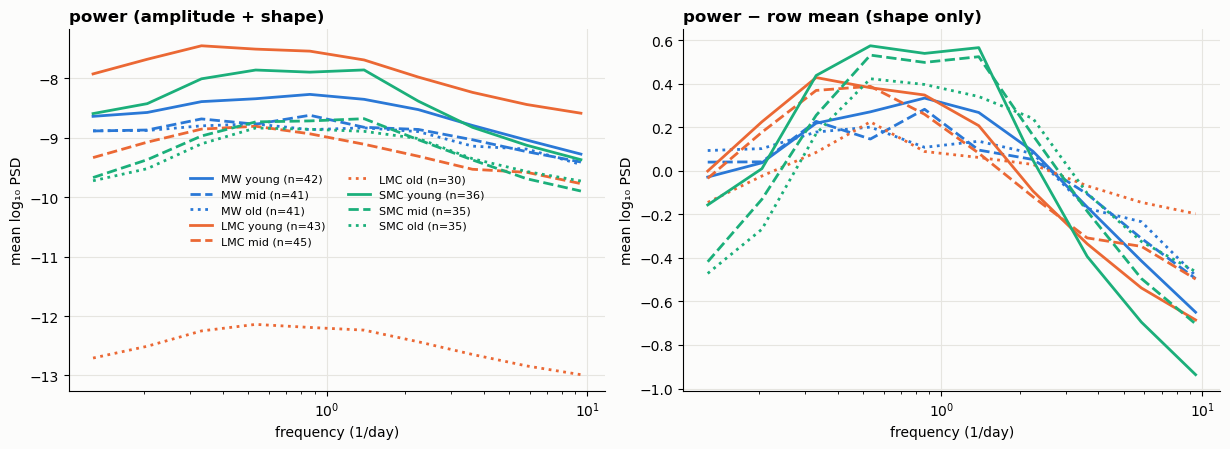

CONCLUSION —
  Largest young-to-old separation in any bin: 4.83 dex with amplitude,
  0.49 dex once amplitude is divided out.
  The spectra differ in SHAPE between young and old clusters, not only in overall level,
  so the shape-only model below has something to find.


In [4]:
fig, axs = plt.subplots(1, 2, figsize=(12.4, 4.6), sharex=True)
styles = ['-', '--', ':']
for o in [g for g in ['MW', 'LMC', 'SMC'] if (clusters.origin == g).sum() >= 40]:
    sub = clusters[clusters.origin == o]
    q = pd.qcut(sub.age, 3, labels=['young', 'mid', 'old'], duplicates='drop')
    for lab, ls in zip(q.cat.categories, styles):
        m = (q == lab).values
        axs[0].plot(CENTERS, np.nanmean(sub[PCOLS].values[m], axis=0), ls,
                    color=COLOURS.get(o, '#8f8e88'), lw=2,
                    label=f'{o} {lab} (n={m.sum()})')
        axs[1].plot(CENTERS, np.nanmean(sub[SCOLS].values[m], axis=0), ls,
                    color=COLOURS.get(o, '#8f8e88'), lw=2)
for ax, ttl in zip(axs, ['power (amplitude + shape)', 'power − row mean (shape only)']):
    ax.set(xscale='log', xlabel='frequency (1/day)', ylabel='mean log₁₀ PSD')
    ax.set_title(ttl, loc='left', fontweight='bold')
axs[0].legend(fontsize=8, ncol=2)
plt.tight_layout(); plt.show()

spread_amp, spread_shape = [], []
for o in clusters.origin.unique():
    sub = clusters[clusters.origin == o]
    if len(sub) < 40: continue
    q = pd.qcut(sub.age, 3, labels=False, duplicates='drop')
    A_ = np.array([np.nanmean(sub[PCOLS].values[q == i], axis=0) for i in range(3)])
    S_ = np.array([np.nanmean(sub[SCOLS].values[q == i], axis=0) for i in range(3)])
    spread_amp.append(np.nanmax(np.ptp(A_, axis=0))); spread_shape.append(np.nanmax(np.ptp(S_, axis=0)))
print('CONCLUSION —')
print(f'  Largest young-to-old separation in any bin: {max(spread_amp):.2f} dex with amplitude,')
print(f'  {max(spread_shape):.2f} dex once amplitude is divided out.')
if max(spread_shape) > 0.15:
    print('  The spectra differ in SHAPE between young and old clusters, not only in overall level,')
    print('  so the shape-only model below has something to find.')
else:
    print('  Almost all of the young/old difference is a vertical shift: older clusters have less')
    print('  power at every frequency. Expect the shape-only model to add little over nuisances.')

## 2 · Six feature sets

All share the nuisance block, the forest and the held-out clusters of notebooks 2 and 4.

pool 278 clusters | holdout 70 clusters


               nuisance only:  10 cols | CV R2 +0.154 +/- 0.141 | holdout R2 +0.282


            GP+LSP summaries:  33 cols | CV R2 +0.200 +/- 0.099 | holdout R2 +0.113


          spectrum (10 bins):  20 cols | CV R2 +0.186 +/- 0.107 | holdout R2 +0.204


         spectrum shape only:  20 cols | CV R2 +0.203 +/- 0.093 | holdout R2 +0.214


          spectrum amplitude:  11 cols | CV R2 +0.206 +/- 0.131 | holdout R2 +0.230


        summaries + spectrum:  43 cols | CV R2 +0.182 +/- 0.099 | holdout R2 +0.127


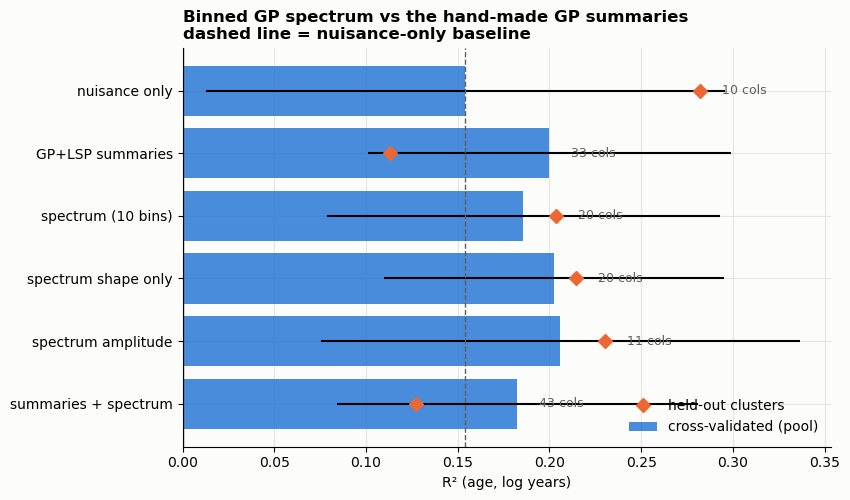

CONCLUSION —
  Gain over nuisance-only (CV): GP+LSP summaries +0.046, spectrum (10 bins) +0.032, spectrum shape only +0.048, spectrum amplitude +0.052, summaries + spectrum +0.028
  Bins and summaries are equivalent; the summaries are a fair compression of the curve.
  Shape alone gains +0.048 over nuisances, so the FORM of the
  variability spectrum tracks age independently of brightness. That is the result worth
  chasing: it cannot be explained by a noise floor.
  Combining both adds -0.018 over the better half — they are the same information twice.


In [5]:
HOLD = A.holdout_by_cluster(clusters.name.values, y=y, frac=0.2, seed=SEED)
POOL = ~HOLD
y_p, y_h = y[POOL], y[HOLD]
print(f'pool {POOL.sum()} clusters | holdout {HOLD.sum()} clusters')

X_nuis = A.design_matrix(clusters, NUISANCES, add_const=False)
num = lambda cols: clusters[cols].apply(pd.to_numeric, errors='coerce')
SETS = {
    'nuisance only':        None,
    'GP+LSP summaries':     num(FEATURES),                      # = notebook 2 'full'
    'spectrum (10 bins)':   num(PCOLS),
    'spectrum shape only':  num(SCOLS),
    'spectrum amplitude':   num([LEVEL]),
    'summaries + spectrum': num(FEATURES + PCOLS),
}
with_n = lambda Xf: (pd.concat([X_nuis, Xf], axis=1) if Xf is not None else X_nuis)
pool_sets = {k: with_n(v)[POOL] for k, v in SETS.items()}
hold_sets = {k: with_n(v)[HOLD] for k, v in SETS.items()}

res = evaluate(pool_sets, y_p, hold_sets, y_h)
plot_sets(res, 'Binned GP spectrum vs the hand-made GP summaries')

r = res.set_index('model')
base, base_h = r.loc['nuisance only', 'r2'], r.loc['nuisance only', 'holdout_r2']
gain = (r.r2 - base).round(3)
print('CONCLUSION —')
print('  Gain over nuisance-only (CV): ' + ', '.join(f'{k} {v:+.3f}' for k, v in gain.items() if k != 'nuisance only'))
d_bins = gain['spectrum (10 bins)'] - gain['GP+LSP summaries']
if d_bins > 0.02:
    print(f'  The 10 bins beat all {len(FEATURES)} summary columns by {d_bins:+.3f} R2. The hand-made GP')
    print('  features are discarding structure the raw spectrum keeps.')
elif d_bins < -0.02:
    print(f'  The summaries beat the bins by {-d_bins:+.3f} R2 — the binning is too coarse, or the')
    print('  LSP/light-curve columns in the summary set carry information no GP spectrum has.')
else:
    print('  Bins and summaries are equivalent; the summaries are a fair compression of the curve.')
if gain['spectrum shape only'] > 0.02:
    print(f'  Shape alone gains {gain["spectrum shape only"]:+.3f} over nuisances, so the FORM of the')
    print('  variability spectrum tracks age independently of brightness. That is the result worth')
    print('  chasing: it cannot be explained by a noise floor.')
else:
    print(f'  Shape alone gains only {gain["spectrum shape only"]:+.3f}: essentially all the spectral')
    print(f'  information is the overall level (amplitude alone gains {gain["spectrum amplitude"]:+.3f}),')
    print('  which is the same amplitude result notebook 1 found, not a new one.')
d_join = gain['summaries + spectrum'] - max(gain['GP+LSP summaries'], gain['spectrum (10 bins)'])
print(f'  Combining both adds {d_join:+.3f} over the better half — ' +
      ('they carry partly separate information.' if d_join > 0.02 else 'they are the same information twice.'))

## 3 · Which frequencies matter

Permutation importance bin by bin, on the spectrum-only model. The x-axis is frequency, so
this is readable as a spectrum in its own right: where does age information live?

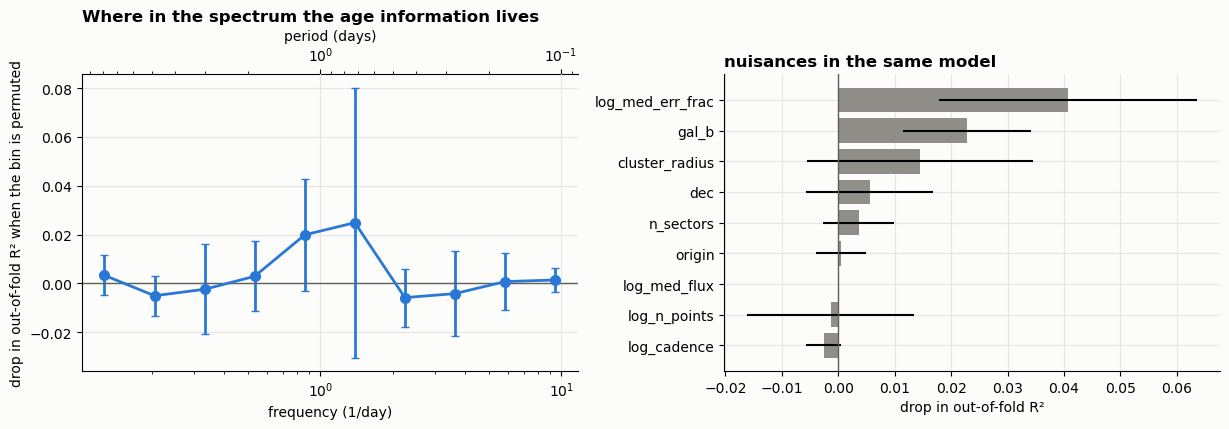

CONCLUSION —
  Most informative bin: 1.39 /day (period 0.72 d), importance +0.0249 +/- 0.0553.
  Summed over bins +0.0354 vs +0.0838 for nuisances.
  Neighbouring bins are strongly correlated, so a single tall bar is not a narrow feature —
  read the envelope, not the individual bin. Bins whose bar is smaller than its error are
  indistinguishable from noise.


In [6]:
from collections import defaultdict
X_use, y_use = pool_sets['spectrum (10 bins)'], y_p
cv = RepeatedKFold(n_splits=5, n_repeats=2, random_state=SEED)
rng = np.random.default_rng(SEED)
imp = defaultdict(list)
origin_cols = [c for c in X_use.columns if c.startswith('origin_')]
blocks = {c: [c] for c in X_use.columns if c not in origin_cols}
if origin_cols: blocks['origin'] = origin_cols
for k, (tr, te) in enumerate(cv.split(X_use, y_use)):
    m = make_forest(SEED + k).fit(X_use.iloc[tr], y_use[tr])
    Xte, yte = X_use.iloc[te], y_use[te]
    b = r2_score(yte, m.predict(Xte))
    for name, cols in blocks.items():
        d = []
        for _ in range(6):
            Xp = Xte.copy()
            Xp[cols] = Xp[cols].to_numpy()[rng.permutation(len(Xp))]
            d.append(b - r2_score(yte, m.predict(Xp)))
        imp[name].append(np.mean(d))
impdf = pd.DataFrame({'column': list(imp), 'importance': [np.mean(v) for v in imp.values()],
                      'sd': [np.std(v) for v in imp.values()]})

bin_imp = impdf[impdf.column.isin(PCOLS)].set_index('column').reindex(PCOLS)
fig, axs = plt.subplots(1, 2, figsize=(12.4, 4.4))
axs[0].errorbar(CENTERS, bin_imp.importance, yerr=bin_imp.sd, marker='o', ms=7, lw=2,
                color='#2a78d6', capsize=3)
axs[0].axhline(0, color='#5f5e5a', lw=1)
axs[0].set(xscale='log', xlabel='frequency (1/day)',
           ylabel='drop in out-of-fold R² when the bin is permuted')
axs[0].set_title('Where in the spectrum the age information lives', loc='left', fontweight='bold')
sec = axs[0].secondary_xaxis('top', functions=(lambda f: 1 / np.maximum(f, 1e-9),
                                               lambda P: 1 / np.maximum(P, 1e-9)))
sec.set_xlabel('period (days)')

nui = impdf[~impdf.column.isin(PCOLS)].sort_values('importance', ascending=False)
axs[1].barh(nui.column.iloc[::-1], nui.importance.iloc[::-1], xerr=nui.sd.iloc[::-1], color='#8f8e88')
axs[1].axvline(0, color='#5f5e5a', lw=1)
axs[1].set(xlabel='drop in out-of-fold R²')
axs[1].set_title('nuisances in the same model', loc='left', fontweight='bold')
plt.tight_layout(); plt.show()

kbest = int(np.nanargmax(bin_imp.importance.values))
print('CONCLUSION —')
print(f'  Most informative bin: {CENTERS[kbest]:.2f} /day (period {1/CENTERS[kbest]:.2f} d), '
      f'importance {bin_imp.importance.iloc[kbest]:+.4f} +/- {bin_imp.sd.iloc[kbest]:.4f}.')
print(f'  Summed over bins {bin_imp.importance.sum():+.4f} vs {nui.importance.sum():+.4f} for nuisances.')
print('  Neighbouring bins are strongly correlated, so a single tall bar is not a narrow feature —')
print('  read the envelope, not the individual bin. Bins whose bar is smaller than its error are')
print('  indistinguishable from noise.')

## 4 · Result table

In [7]:
res.to_csv('results_rf_spectrum_ablation.csv', index=False)
impdf.to_csv('results_rf_spectrum_importances.csv', index=False)
display(res.round(3))
print('wrote results_rf_spectrum_ablation.csv, results_rf_spectrum_importances.csv')
print()
print('CONCLUSION —')
best = res.sort_values('holdout_r2', ascending=False).iloc[0]
print(f'  Best on the held-out clusters: "{best.model}" at R2 {best.holdout_r2:+.3f} '
      f'({int(best.n_cols)} columns, CV {best.r2:+.3f}).')
print('  Caveat that applies to every row: the GP spectrum is a FITTED object, so a bin can')
print('  carry age information because the fit behaves differently on faint or short light')
print('  curves. The nuisance block absorbs the obvious part of that; gp_rn_near_white_noise')
print('  and gp_components_capped are fit outcomes and are deliberately not controls (see')
print('  analysis_utils), so a sensitivity check that drops flagged clusters belongs here')
print('  before any of this is quoted.')

,model,n_cols,r2,r2_sd,mae,holdout_r2,holdout_mae
0,nuisance only,10,0.154,0.141,0.470,0.282,0.516
1,GP+LSP summaries,33,0.200,0.099,0.458,0.113,0.554
2,spectrum (10 bins),20,0.186,0.107,0.461,0.204,0.534
3,spectrum shape only,20,0.203,0.093,0.459,0.214,0.527
4,spectrum amplitude,11,0.206,0.131,0.456,0.230,0.527
5,summaries + spectrum,43,0.182,0.099,0.463,0.127,0.549


wrote results_rf_spectrum_ablation.csv, results_rf_spectrum_importances.csv

CONCLUSION —
  Best on the held-out clusters: "nuisance only" at R2 +0.282 (10 columns, CV +0.154).
  Caveat that applies to every row: the GP spectrum is a FITTED object, so a bin can
  carry age information because the fit behaves differently on faint or short light
  curves. The nuisance block absorbs the obvious part of that; gp_rn_near_white_noise
  and gp_components_capped are fit outcomes and are deliberately not controls (see
  analysis_utils), so a sensitivity check that drops flagged clusters belongs here
  before any of this is quoted.
